In [1]:
# 03 - Decision Tree (TP4): Decision Tree classification on ourdataset + classification metrics + MLflow
#
# Like course 4 (the diabetes notebook), but on our heart sounds (ourdataset).
# The project plan says: "Decision Tree (Arbre de Décision) sur caractéristiques 1D (MFCC)"
#   -> for each wav we compute 1D features (1 list of numbers per wav). 2 feature sets are compared:
#      - my 26 MFCC features (mean + std of 13 MFCC on the middle 5 s)
#      - Zaineb's 72 features (whole wav): the same kind of MFCC + Mel bands + spectral centroid + ZCR + SNR + duration
#        (merge of our 2 works: on the same folds her features gave a better recall, see MERGE_NOTES.md)
#
# Protocol (the same in all the model notebooks):
#   - the fixed TEST set of notebook 01 (20% of the wavs) is put aside: never used to train or to choose a setting
#   - the feature set, the criterion and the max_depth are chosen with the 3 folds of the 80% train part
#     (Zaineb's idea: choose the depth on the train part only, never on the test wavs)
#   - VALIDATION = the 3 folds with the chosen settings | TEST = the final tree (trained on the 80%) on the 20%
#
# MLflow (experiment audio_benchmark_final): 1 run for the tree + inside it, 1 small run per fold
#
# Before running: notebook 01 made splits/test_files.json, and the MLflow container runs (docker start mlflow-server)

In [2]:
import os
import json
import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import requests                                                  # only to check that MLflow is running
import IPython.display as ipd

from sklearn.model_selection import KFold
from sklearn.model_selection import learning_curve                # the training vs validation curves
from sklearn.tree import DecisionTreeClassifier, plot_tree        # the decision tree + a function to draw it
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc                        # the ROC curve and the area under it (AUC)

import mlflow
import mlflow.sklearn

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:    # "wb" = write binary
        pickle.dump(data, f)


# MLflow (Service 6): our server = the Docker container "mlflow-server", on port 5000
mlflow.set_tracking_uri("http://localhost:5000")
try:
    requests.get("http://localhost:5000/health", timeout=3)    # is the server there?
    mlflow.set_experiment("audio_benchmark_final")    # the experiment of the final protocol (validation + test)
    print("MLflow server: OK")
except requests.exceptions.ConnectionError:
    print("MLflow server NOT running -> run 'docker start mlflow-server' in the terminal, then run this cell again")

2026/11/26 20:19:49 INFO mlflow.tracking.fluent: Experiment with name 'audio_benchmark_final' does not exist. Creating a new experiment.


MLflow server: OK


In [4]:
# ==================== The features: 2 lists of 1D numbers for each wav ====================
# MFCC = a summary of the Mel spectrogram (course 2): log of the Mel spectrogram + one more math step (DCT)
#        -> 13 numbers per moment that describe the "shape" of the sound (the classic features for sounds)
SR = 2000          # every wav at 2000 Hz (like TP3 and the project plan)
SECONDS = 5        # every wav = 5 seconds (the project plan: "normalisation 2s ou 5s")
N_MFCC = 13        # 13 MFCC coefficients (the classic number)

# the same cleaning rules as notebook 01 and TP3, so we keep the same wavs as the SVM
MIN_DURATION = 2       # seconds
MIN_PEAK = 0.001       # almost no sound
MAX_CLIPPING = 1       # % of saturated samples


def signaltonoise(a, axis=0, ddof=0):
    # the SNR function of the course (TP1): mean / standard deviation
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)


def get_extended_features(signal):
    # Zaineb's 72 features, on the WHOLE wav (n_fft = 512, hop = 128, 20 Mel bands):
    # duration, SNR | mean and std of each Mel band (20 + 20) | mean and std of 13 MFCC (13 + 13)
    # | mean and std of the spectral centroid (where the "centre" of the frequencies is) | mean and std of the ZCR
    duration = len(signal) / SR
    snr = float(signaltonoise(signal / max(np.max(np.abs(signal)), 1e-10)))
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=20)
    S_DB = librosa.power_to_db(S, ref=np.max)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=13, n_fft=512, hop_length=128, n_mels=20)
    centroid = librosa.feature.spectral_centroid(y=signal, sr=SR, n_fft=512, hop_length=128)
    zcr = librosa.feature.zero_crossing_rate(signal, frame_length=512, hop_length=128)
    return ([duration, snr] + list(np.mean(S_DB, axis=1)) + list(np.std(S_DB, axis=1))
            + list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))
            + [np.mean(centroid), np.std(centroid), np.mean(zcr), np.std(zcr)])


def get_mfcc_features(signal):
    # my 26 features: the same duration for every wav (like TP3): the middle 5 s, a shorter wav is repeated
    n_samples = SR * SECONDS
    if len(signal) < n_samples:
        repeat = int(np.ceil(n_samples / len(signal)))
        signal = np.tile(signal, repeat)[:n_samples]
    else:
        start = (len(signal) - n_samples) // 2
        signal = signal[start:start + n_samples]

    # MFCC: a table of 13 rows (the coefficients) x 1 column per moment (every 0.064 s)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=N_MFCC, n_fft=256, hop_length=128, n_mels=30)

    # 1D features: the mean and the std of each coefficient over the 5 s -> 13 + 13 = 26 numbers
    return list(np.mean(mfcc, axis=1)) + list(np.std(mfcc, axis=1))


def extract_features():
    a = []          # my 26 MFCC features of each wav
    a72 = []        # Zaineb's 72 features of each wav
    b = []          # the class of each wav: 1 = abnormal, 0 = normal
    names = []      # the name of each wav: to find the wavs of the test set
    removed = 0
    for nametype in ["abnormal", "normal"]:
        for file in glob(ourdataset_folder + nametype + "/*.wav"):
            signal, rate = librosa.load(file, sr=SR)

            # cleaning: a broken wav is skipped
            duration = len(signal) / rate
            peak = np.max(np.abs(signal))
            clipping_pct = 100 * np.mean(np.abs(signal) >= 0.99)
            if duration < MIN_DURATION or peak < MIN_PEAK or clipping_pct > MAX_CLIPPING:
                removed = removed + 1
                continue

            a.append(get_mfcc_features(signal))
            a72.append(get_extended_features(signal))
            names.append(os.path.basename(file))
            if nametype == "normal":
                b.append(0)
            else:
                b.append(1)

    # saved like the prof's files: a = the features, b = the classes
    save_data(a, project_folder + "mfcc_features_tree_a.data")
    save_data(b, project_folder + "mfcc_features_tree_b.data")
    save_data(a72, project_folder + "extended_features_72.data")
    save_data(names, project_folder + "tree_files.data")
    print("removed", removed, "broken wavs | kept", len(a), "wavs x", len(a[0]), "MFCC features and",
          len(a72[0]), "extended features")
    return a, a72, b, names

In [5]:
# reads all the wavs (a few minutes). Run it once: after that, the .data files are enough
a, a72, b, names = extract_features()

removed 85 broken wavs | kept 3681 wavs x 26 MFCC features and 72 extended features


26 MFCC : dimension of our data: (3681, 26)
72 extended : dimension of our data: (3681, 72)
normal (0): 2855 | abnormal (1): 826


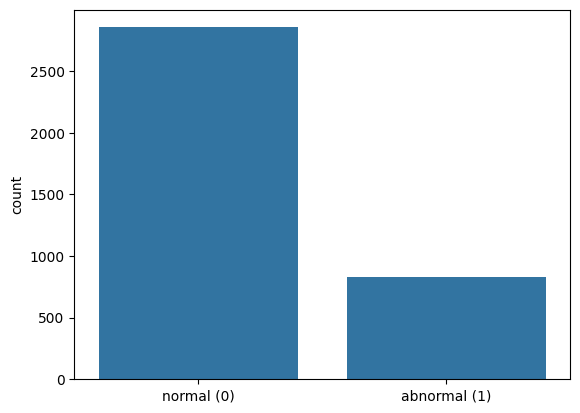

,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean,mfcc5_mean,mfcc6_mean,mfcc7_mean,mfcc8_mean,mfcc9_mean,mfcc10_mean,...,mfcc4_std,mfcc5_std,mfcc6_std,mfcc7_std,mfcc8_std,mfcc9_std,mfcc10_std,mfcc11_std,mfcc12_std,mfcc13_std
0,-254.894684,20.302010,29.536432,22.771187,10.476133,12.026559,6.437137,4.289824,2.640546,5.904438,...,4.668721,4.105862,3.484509,2.995849,3.251541,3.373689,3.227825,3.025101,3.285295,2.767606
1,-264.525269,47.955196,31.116093,13.411427,6.604259,3.859557,1.145443,2.723909,0.902089,3.090525,...,6.344787,7.899178,6.719737,4.280223,3.589770,3.174209,3.024146,3.097579,2.866457,3.003225
2,-297.487000,36.259377,45.223820,14.961040,18.376766,7.381001,10.361653,0.739179,7.681967,1.390419,...,4.866203,7.645961,3.329160,4.869174,3.549373,3.531684,3.013973,2.806368,3.124293,2.958954
3,-280.577179,54.925072,30.691113,23.961609,6.546364,9.328610,2.989173,1.685358,3.512840,0.734703,...,6.438685,6.458922,5.211511,4.799251,5.480114,6.822571,5.312037,3.544802,4.099167,3.872746
4,-266.613495,57.948544,30.325579,22.595510,17.173113,12.237260,6.241416,4.622953,5.561380,5.021791,...,6.070164,7.609652,5.870015,4.180736,3.832866,3.392121,3.408708,3.172079,2.745392,2.679134


In [6]:
a = load_data(project_folder + "mfcc_features_tree_a.data")
b = load_data(project_folder + "mfcc_features_tree_b.data")
a72 = load_data(project_folder + "extended_features_72.data")
files = np.array(load_data(project_folder + "tree_files.data"))

X_sets = {"26 MFCC": np.array(a), "72 extended": np.array(a72)}    # the 2 feature sets (1 row per wav)
y = np.array(b)    # 0 = normal, 1 = abnormal

# the names of the features: mfcc1_mean ... mfcc13_mean, then mfcc1_std ... mfcc13_std (26), and the 72
feature_names = {"26 MFCC": [], "72 extended": ["duration", "snr"]}
for i in range(1, N_MFCC + 1):
    feature_names["26 MFCC"].append("mfcc" + str(i) + "_mean")
for i in range(1, N_MFCC + 1):
    feature_names["26 MFCC"].append("mfcc" + str(i) + "_std")
for stat in ["mean", "std"]:
    for i in range(1, 21):
        feature_names["72 extended"].append("mel" + str(i) + "_" + stat)
for stat in ["mean", "std"]:
    for i in range(1, N_MFCC + 1):
        feature_names["72 extended"].append("mfcc" + str(i) + "_" + stat)
feature_names["72 extended"] += ["centroid_mean", "centroid_std", "zcr_mean", "zcr_std"]

for name in X_sets:
    print(name, ": dimension of our data:", X_sets[name].shape)
print("normal (0):", np.sum(y == 0), "| abnormal (1):", np.sum(y == 1))

sns.countplot(x=y)    # like the course: how many wavs in each class
plt.xticks([0, 1], ["normal (0)", "abnormal (1)"])
plt.show()

pd.DataFrame(X_sets["26 MFCC"], columns=feature_names["26 MFCC"]).head()

In [7]:
# The formulas of the course, on our data (before the first question of the tree)
p_normal = np.mean(y == 0)
p_abnormal = np.mean(y == 1)

gini = 1 - p_normal ** 2 - p_abnormal ** 2                                    # Gini impurity
entropy = -(p_normal * np.log2(p_normal) + p_abnormal * np.log2(p_abnormal))  # entropy (ID3, Quinlan)

print("p(normal) = {:.3f} | p(abnormal) = {:.3f}".format(p_normal, p_abnormal))
print("Gini impurity = {:.3f}   (0 = only 1 class, 0.5 = 50/50)".format(gini))
print("Entropy       = {:.3f}   (0 = only 1 class, 1 = 50/50)".format(entropy))
# The tree looks for the question "feature <= threshold" (like "Weight < 167.5" in the course)
# that makes the 2 groups the most pure (the biggest gain), then again in each group, and so on

p(normal) = 0.776 | p(abnormal) = 0.224
Gini impurity = 0.348   (0 = only 1 class, 0.5 = 50/50)
Entropy       = 0.768   (0 = only 1 class, 1 = 50/50)


In [8]:
# ==================== The fixed TEST set (made by notebook 01): put aside, never used to train ====================
# - 80% = the TRAIN part: the choice of the settings, the 3 folds (validation) and the final tree
# - 20% = the TEST part: used ONCE at the end, to test the final tree
with open(project_folder + "splits/test_files.json") as f:
    split = json.load(f)
test_label = dict(zip(split["test_files"], split["test_labels"]))    # name of a test wav -> its class

assert len(files) == len(y) == len(X_sets["26 MFCC"]) == len(X_sets["72 extended"])
is_test = np.array([name in test_label for name in files])          # True for the 20% test wavs
assert is_test.sum() == split["n_test"], "some test wavs are missing: run notebook 01 again"
for i in np.where(is_test)[0]:
    assert y[i] == test_label[files[i]], "the class of " + files[i] + " is not the same in notebook 01"

y_train, y_test = y[~is_test], y[is_test]    # ~ = "not": the 80% train part
print("train (80%):", len(y_train), "wavs | test (20%):", len(y_test), "wavs")

kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the same 3 folds as TP3, TP7 and TP8

train (80%): 2944 wavs | test (20%): 737 wavs


Best tree: features = 72 extended | criterion = gini | max_depth = 8 | mean validation F1 = 0.660
Best validation F1 of each feature set:
features
26 MFCC        0.654
72 extended    0.660
Name: val_f1, dtype: float64


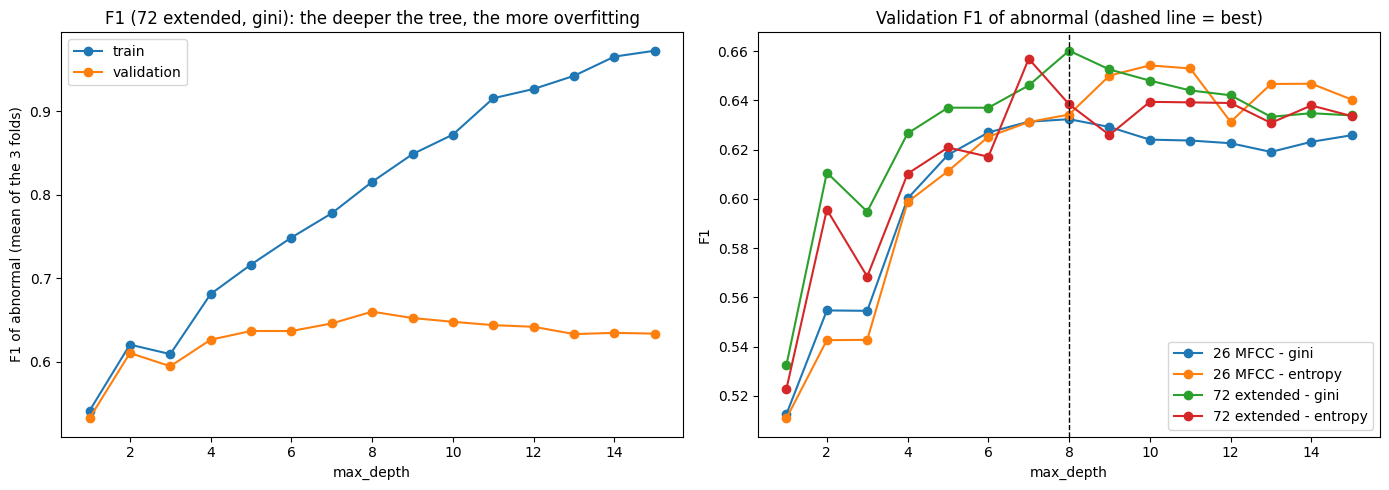

In [9]:
# 2. Which features, which criterion ("gini" or "entropy", both in the course) and which max_depth?
#    We try every combination with the 3 folds of the 80% train part and look at the validation wavs of each fold.
#    The test wavs are NOT used here (Zaineb's idea: choosing on the test wavs makes the test score too optimistic).
#    Score to choose = the F1 of abnormal: it balances the recall (find the sick hearts) and the precision
#    (not too many false alarms). With the recall alone, a tiny tree that says "abnormal" too often would win.
rows = []
for set_name in X_sets:
    X_train = X_sets[set_name][~is_test]
    for criterion in ["gini", "entropy"]:
        for depth in range(1, 16):
            train_f1 = []
            val_f1 = []
            for train_index, val_index in kfold.split(X_train):
                tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, class_weight="balanced",
                                              random_state=0)
                tree.fit(X_train[train_index], y_train[train_index])
                train_f1.append(f1_score(y_train[train_index], tree.predict(X_train[train_index])))
                val_f1.append(f1_score(y_train[val_index], tree.predict(X_train[val_index])))
            rows.append({"features": set_name, "criterion": criterion, "max_depth": depth,
                         "train_f1": np.mean(train_f1), "val_f1": np.mean(val_f1)})
search = pd.DataFrame(rows)

best = search.loc[search["val_f1"].idxmax()]    # idxmax = the first maximum = the smallest depth if there is a tie
best_features = best["features"]
best_criterion = best["criterion"]
best_depth = int(best["max_depth"])
print("Best tree: features =", best_features, "| criterion =", best_criterion, "| max_depth =", best_depth,
      "| mean validation F1 = {:.3f}".format(best["val_f1"]))
print("Best validation F1 of each feature set:")
print(search.groupby("features")["val_f1"].max().round(3))

# ONE figure: left = the overfitting (train vs validation), right = the validation F1 of every combination
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
chosen = search[(search["features"] == best_features) & (search["criterion"] == best_criterion)]
plt.plot(chosen["max_depth"], chosen["train_f1"], marker="o", label="train")
plt.plot(chosen["max_depth"], chosen["val_f1"], marker="o", label="validation")
plt.title("F1 (" + best_features + ", " + best_criterion + "): the deeper the tree, the more overfitting")
plt.xlabel("max_depth")
plt.ylabel("F1 of abnormal (mean of the 3 folds)")
plt.legend()

plt.subplot(1, 2, 2)
for set_name in X_sets:
    for criterion in ["gini", "entropy"]:
        part = search[(search["features"] == set_name) & (search["criterion"] == criterion)]
        plt.plot(part["max_depth"], part["val_f1"], marker="o", label=set_name + " - " + criterion)
plt.axvline(best_depth, color="black", linestyle="--", linewidth=1)    # the best max_depth
plt.title("Validation F1 of abnormal (dashed line = best)")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.legend()

plt.tight_layout()
plt.savefig(plots_folder + "tp4_choose_depth.png")
plt.show()

X_train = X_sets[best_features][~is_test]    # from here: the chosen features only
X_test = X_sets[best_features][is_test]
names_of_features = feature_names[best_features]

In [10]:
# 3. VALIDATION: the 3 folds (like TP3) with the chosen settings
#    each fold: 1 third of the train part = validation, the 2 other thirds = train
results = []               # the metrics of each fold
fold = 1
for train_index, val_index in kfold.split(X_train):
    X_tr, X_val = X_train[train_index], X_train[val_index]
    y_tr, y_val = y_train[train_index], y_train[val_index]

    tree = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced", random_state=0)
    tree.fit(X_tr, y_tr)
    y_pred = tree.predict(X_val)
    y_score = tree.predict_proba(X_val)[:, 1]    # the % of abnormal train wavs in the leaf: used for the ROC curve
    y_tr_pred = tree.predict(X_tr)               # also on its own train wavs: to compare training vs validation
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_val, y_score)

    print("--- Fold", fold, ": train =", len(train_index), "wavs | validation =", len(val_index), "wavs")
    print(classification_report(y_val, y_pred, target_names=["normal", "abnormal"]))

    results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_val, y_pred),     # % of good answers
        "precision": precision_score(y_val, y_pred),   # these 3: for the abnormal class (1)
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
        "auc": auc(false_positive_rate, true_positive_rate),
        "train_accuracy": accuracy_score(y_tr, y_tr_pred),    # the same metrics on the train wavs
        "train_precision": precision_score(y_tr, y_tr_pred),
        "train_recall": recall_score(y_tr, y_tr_pred),
        "train_f1": f1_score(y_tr, y_tr_pred),
        "cm": confusion_matrix(y_val, y_pred),                # kept to draw them after
        "y_val": y_val,
        "y_score": y_score,
    })
    fold = fold + 1

metrics = ["accuracy", "precision", "recall", "f1", "auc"]
table = pd.DataFrame(results)[["fold"] + metrics]
ipd.display(table.round(3))
print("Mean of the 3 folds (validation):")
print(table[metrics].mean().round(3))

--- Fold 1 : train = 1962 wavs | validation = 982 wavs
              precision    recall  f1-score   support

      normal       0.92      0.83      0.87       756
    abnormal       0.58      0.77      0.66       226

    accuracy                           0.82       982
   macro avg       0.75      0.80      0.77       982
weighted avg       0.84      0.82      0.82       982



--- Fold 2 : train = 1963 wavs | validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.93      0.83      0.88       759
    abnormal       0.58      0.79      0.67       222

    accuracy                           0.82       981
   macro avg       0.76      0.81      0.78       981
weighted avg       0.85      0.82      0.83       981



--- Fold 3 : train = 1963 wavs | validation = 981 wavs
              precision    recall  f1-score   support

      normal       0.93      0.83      0.88       768
    abnormal       0.56      0.77      0.65       213

    accuracy                           0.82       981
   macro avg       0.75      0.80      0.76       981
weighted avg       0.85      0.82      0.83       981



,fold,accuracy,precision,recall,f1,auc
0,1,0.817,0.577,0.765,0.658,0.826
1,2,0.825,0.583,0.793,0.672,0.837
2,3,0.820,0.561,0.775,0.651,0.840


Mean of the 3 folds (validation):
accuracy     0.820
precision    0.574
recall       0.778
f1           0.660
auc          0.834
dtype: float64


In [11]:
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of wavs of class i (true) that the tree put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


def plot_roc(y_true, y_score, title):
    # ROC curve: for every threshold, the % of sick hearts found (true positive rate = recall) against the % of
    # normal hearts called abnormal (false positive rate). AUC = the area under it (1 = perfect, 0.5 = random)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, y_score)
    area = auc(false_positive_rate, true_positive_rate)
    plt.plot(false_positive_rate, true_positive_rate, label="AUC = {:.3f}".format(area))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="random")
    plt.title(title)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate (recall)")
    plt.legend(loc="lower right")
    return area

Fold 1 : training F1 = 0.808 | validation F1 = 0.658 (with all its train wavs)


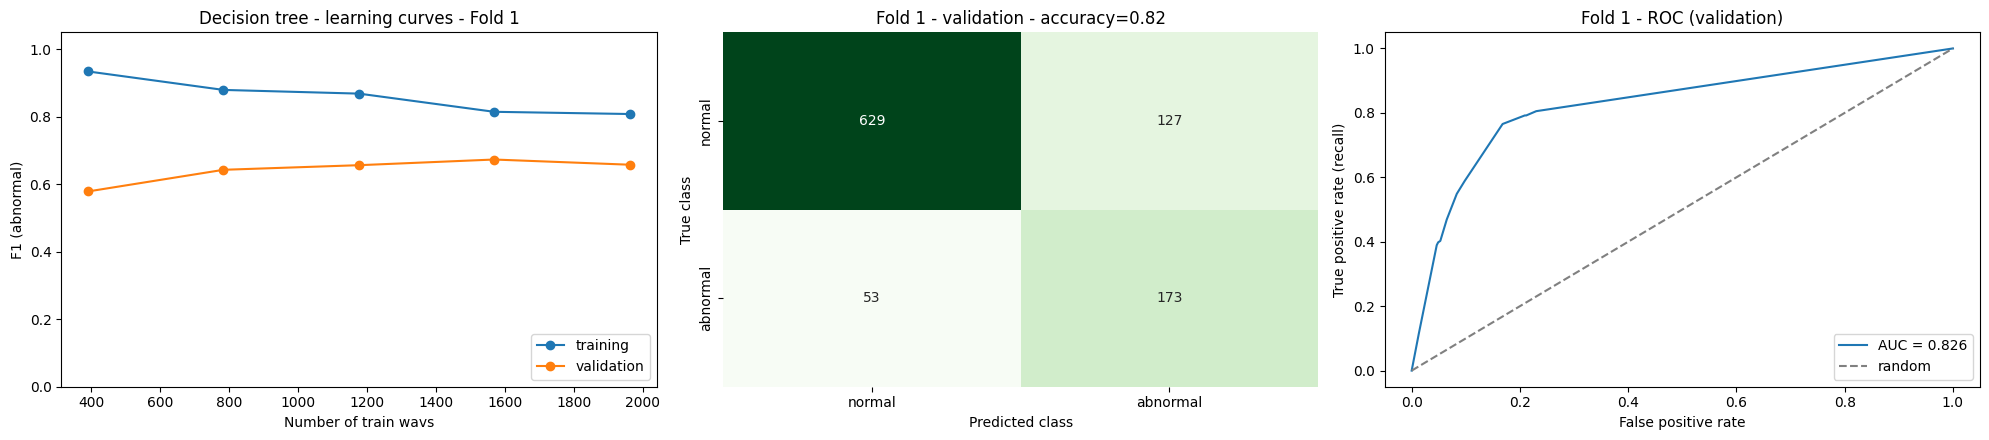

Fold 2 : training F1 = 0.814 | validation F1 = 0.652 (with all its train wavs)


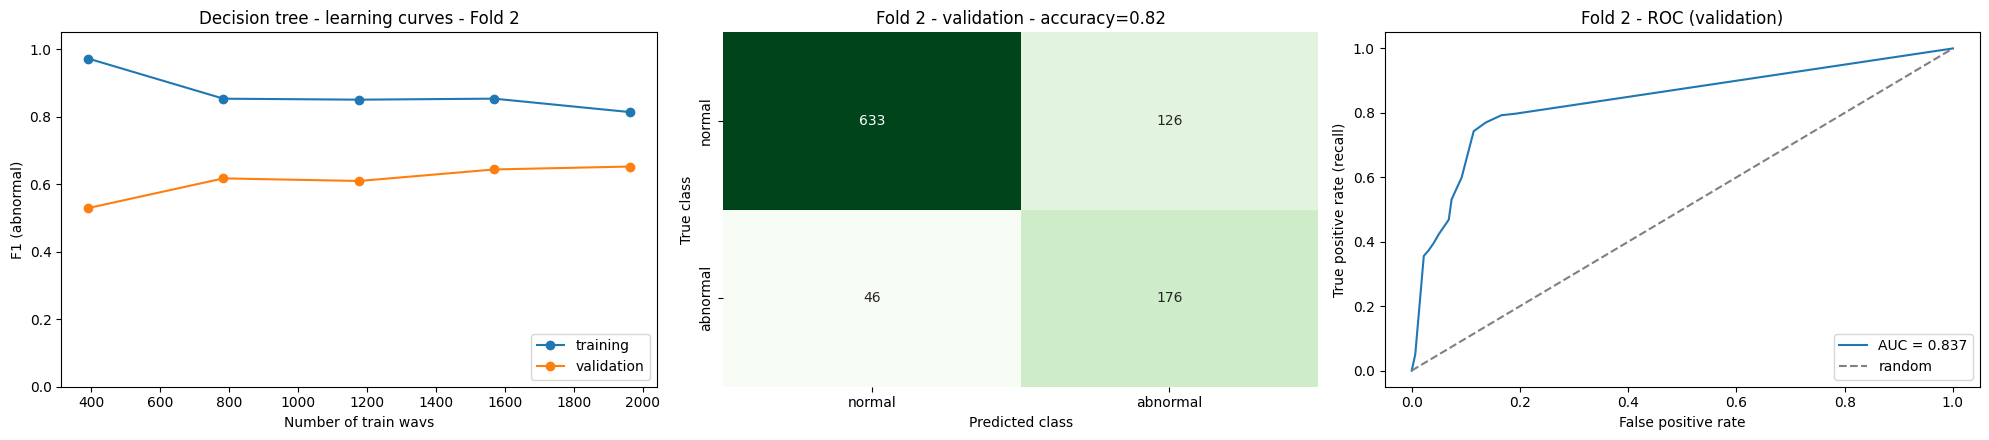

Fold 3 : training F1 = 0.805 | validation F1 = 0.624 (with all its train wavs)


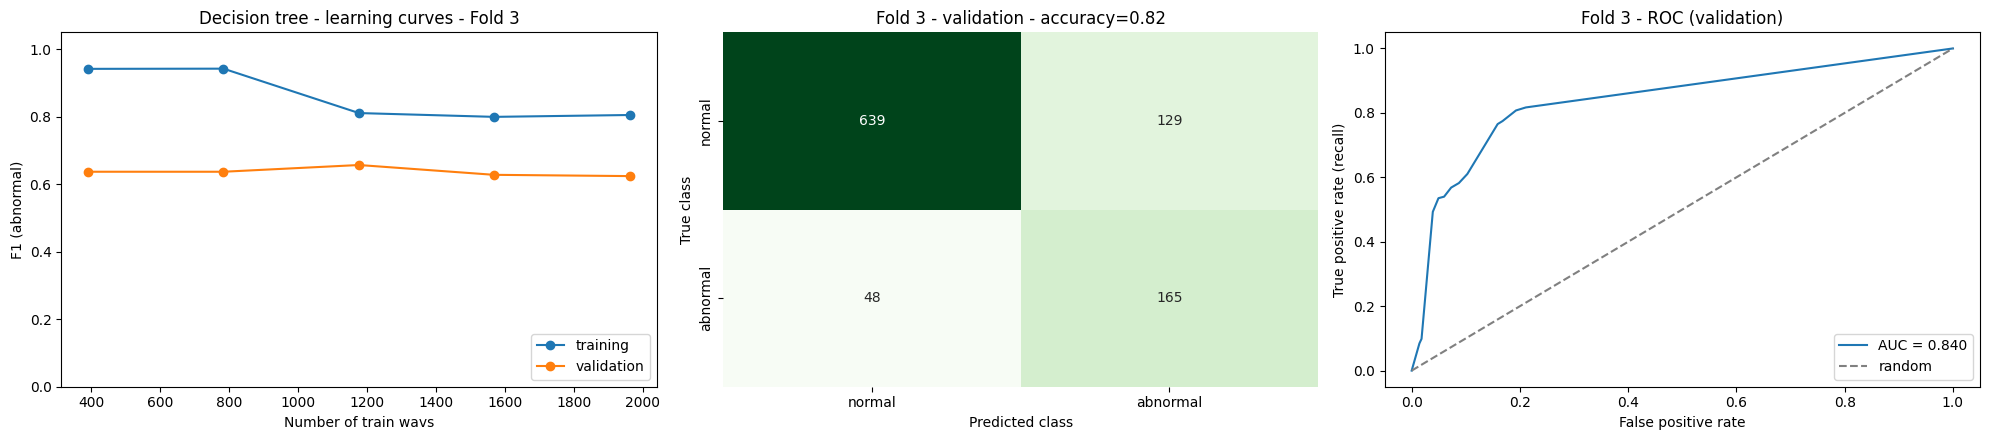

In [12]:
# 4. Training vs validation: the learning curves (the same 3 folds of the train part)
#    For each fold, the tree learns on 20%, 40%, 60%, 80% and 100% of its train wavs. Each time we look at its F1
#    (abnormal) on these train wavs (= training) and on the third of the wavs it never saw (= validation).
#    - a big gap between the 2 curves = overfitting (the tree learns its train wavs by heart)
#    - the validation curve still goes up at the end = more wavs would help
#    shuffle=True: our wavs are sorted (all the abnormal ones first), so they are mixed before taking the 20%, 40%, ...
model = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced", random_state=0)
sizes, train_scores, val_scores = learning_curve(model, X_train, y_train, cv=kfold, scoring="f1",
                                                 train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
                                                 shuffle=True, random_state=0)
# train_scores and val_scores: 1 row per size, 1 column per fold

# 1 figure per fold: its learning curves + its confusion matrix + its ROC curve (validation wavs)
for fold in range(3):
    r = results[fold]
    print("Fold", fold + 1, ": training F1 = {:.3f} | validation F1 = {:.3f} (with all its train wavs)".format(
        train_scores[-1, fold], val_scores[-1, fold]))
    plt.figure(figsize=(20, 4.5))
    plt.subplot(1, 3, 1)
    plt.plot(sizes, train_scores[:, fold], "o-", color="tab:blue", label="training")
    plt.plot(sizes, val_scores[:, fold], "o-", color="tab:orange", label="validation")
    plt.title("Decision tree - learning curves - Fold " + str(fold + 1))
    plt.xlabel("Number of train wavs")
    plt.ylabel("F1 (abnormal)")
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    plt.subplot(1, 3, 2)
    PlotConfusionMatrix(r["cm"], "Fold " + str(fold + 1) + " - validation - accuracy=" + str(round(r["accuracy"], 2)))
    plt.subplot(1, 3, 3)
    plot_roc(r["y_val"], r["y_score"], "Fold " + str(fold + 1) + " - ROC (validation)")
    plt.tight_layout()
    plt.savefig(plots_folder + "tp4_tree_val_fold" + str(fold + 1) + ".png")
    plt.show()

With all the train wavs -> training F1 = 0.809 | validation F1 = 0.645 (mean of the 3 folds)


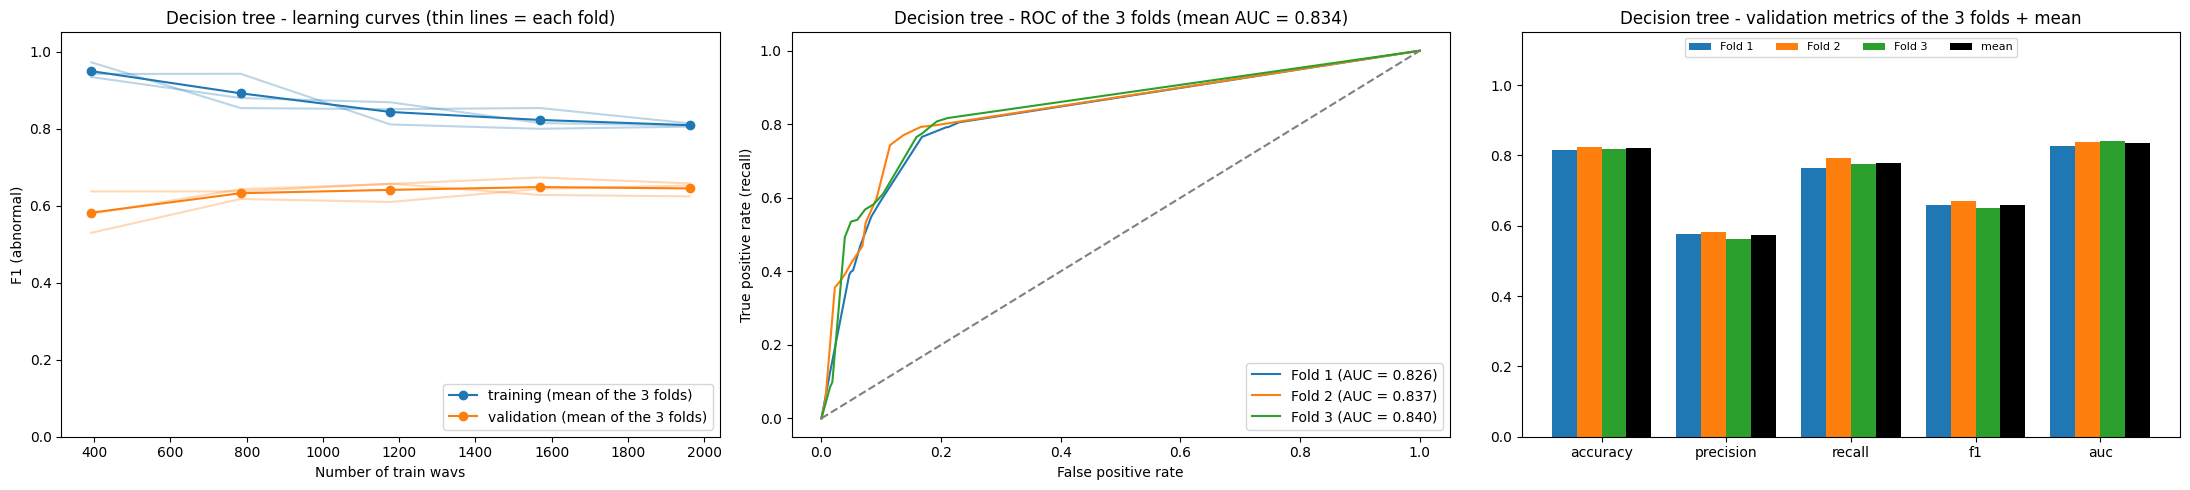

In [13]:
# The summary of the validation: the mean learning curves, the ROC of the 3 folds, the metrics of each fold + the mean
print("With all the train wavs -> training F1 = {:.3f} | validation F1 = {:.3f} (mean of the 3 folds)".format(
    train_scores[-1].mean(), val_scores[-1].mean()))

plt.figure(figsize=(22, 5))
plt.subplot(1, 3, 1)
for fold in range(3):    # thin lines: each fold
    plt.plot(sizes, train_scores[:, fold], color="tab:blue", alpha=0.3)
    plt.plot(sizes, val_scores[:, fold], color="tab:orange", alpha=0.3)
plt.plot(sizes, train_scores.mean(axis=1), "o-", color="tab:blue", label="training (mean of the 3 folds)")
plt.plot(sizes, val_scores.mean(axis=1), "o-", color="tab:orange", label="validation (mean of the 3 folds)")
plt.title("Decision tree - learning curves (thin lines = each fold)")
plt.xlabel("Number of train wavs")
plt.ylabel("F1 (abnormal)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")

plt.subplot(1, 3, 2)
for r in results:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(r["y_val"], r["y_score"])
    plt.plot(false_positive_rate, true_positive_rate, label="Fold " + str(r["fold"]) + " (AUC = {:.3f})".format(r["auc"]))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title("Decision tree - ROC of the 3 folds (mean AUC = {:.3f})".format(table["auc"].mean()))
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend(loc="lower right")

plt.subplot(1, 3, 3)
x = np.arange(len(metrics))
for i in range(3):
    plt.bar(x - 0.3 + 0.2 * i, table.loc[i, metrics], width=0.2, label="Fold " + str(i + 1))
plt.bar(x + 0.3, table[metrics].mean(), width=0.2, color="black", label="mean")
plt.xticks(x, metrics)
plt.ylim(0, 1.15)
plt.title("Decision tree - validation metrics of the 3 folds + mean")
plt.legend(loc="upper center", ncol=4, fontsize=8)

plt.tight_layout()
plt.savefig(plots_folder + "tp4_tree_val_summary.png")
plt.show()

Accuracy on training set: 0.901
Accuracy on test set: 0.839
              precision    recall  f1-score   support

      normal       0.93      0.85      0.89       572
    abnormal       0.61      0.79      0.69       165

    accuracy                           0.84       737
   macro avg       0.77      0.82      0.79       737
weighted avg       0.86      0.84      0.85       737



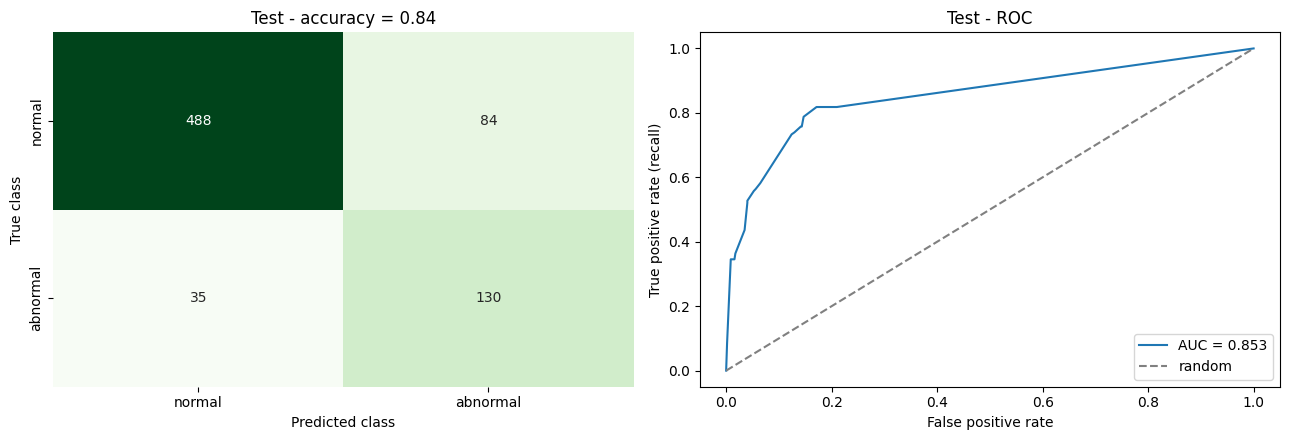

In [14]:
# 5. TEST: the final tree learns on the whole 80% train part, then it is tested ONCE on the 20% test set
final_tree = DecisionTreeClassifier(criterion=best_criterion, max_depth=best_depth, class_weight="balanced",
                                    random_state=0)
final_tree.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(final_tree.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(final_tree.score(X_test, y_test)))

y_test_pred = final_tree.predict(X_test)
y_test_score = final_tree.predict_proba(X_test)[:, 1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_test_score)
test_results = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
    "auc": auc(false_positive_rate, true_positive_rate),
}
report = classification_report(y_test, y_test_pred, target_names=["normal", "abnormal"])
print(report)
with open(plots_folder + "tp4_tree_test_report.txt", "w") as f:
    f.write("Decision tree - test set (" + str(len(y_test)) + " wavs never seen)\n\n" + report)

# ONE test figure: the confusion matrix and the ROC curve of the test wavs
plt.figure(figsize=(13, 4.5))
plt.subplot(1, 2, 1)
PlotConfusionMatrix(confusion_matrix(y_test, y_test_pred), "Test - accuracy = {:.2f}".format(test_results["accuracy"]))
plt.subplot(1, 2, 2)
plot_roc(y_test, y_test_score, "Test - ROC")
plt.tight_layout()
plt.savefig(plots_folder + "tp4_tree_test.png")
plt.show()

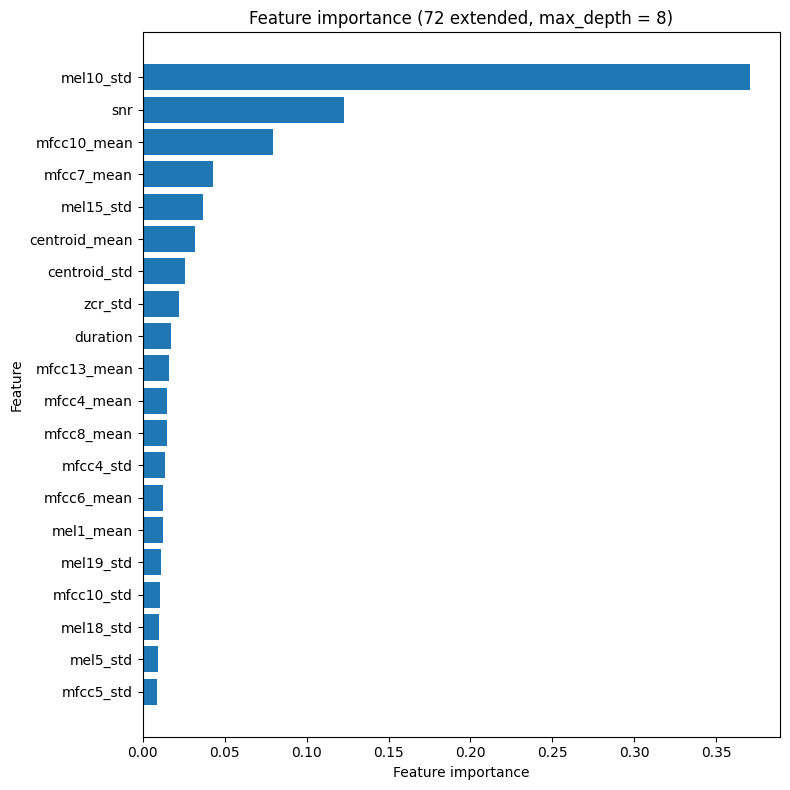

The 5 most important features:
mel10_std      0.370
snr            0.123
mfcc10_mean    0.079
mfcc7_mean     0.043
mel15_std      0.037
dtype: float64
Features never used by the tree: 24 of 72


In [15]:
# 6. Feature importance of the final tree: how much each feature helped the tree to decide
#    (a number between 0 and 1, the sum = 1, 0 = never used)
importances = pd.Series(final_tree.feature_importances_, index=names_of_features).sort_values(ascending=False)
top = importances.head(20)[::-1]    # the 20 most important features (the most important at the top)

plt.figure(figsize=(8, 8))
plt.barh(top.index, top.values)
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Feature importance (" + best_features + ", max_depth = " + str(best_depth) + ")")
plt.tight_layout()
plt.savefig(plots_folder + "tp4_feature_importance.png")
plt.show()

print("The 5 most important features:")
print(importances.head(5).round(3))
print("Features never used by the tree:", np.sum(final_tree.feature_importances_ == 0), "of", len(names_of_features))

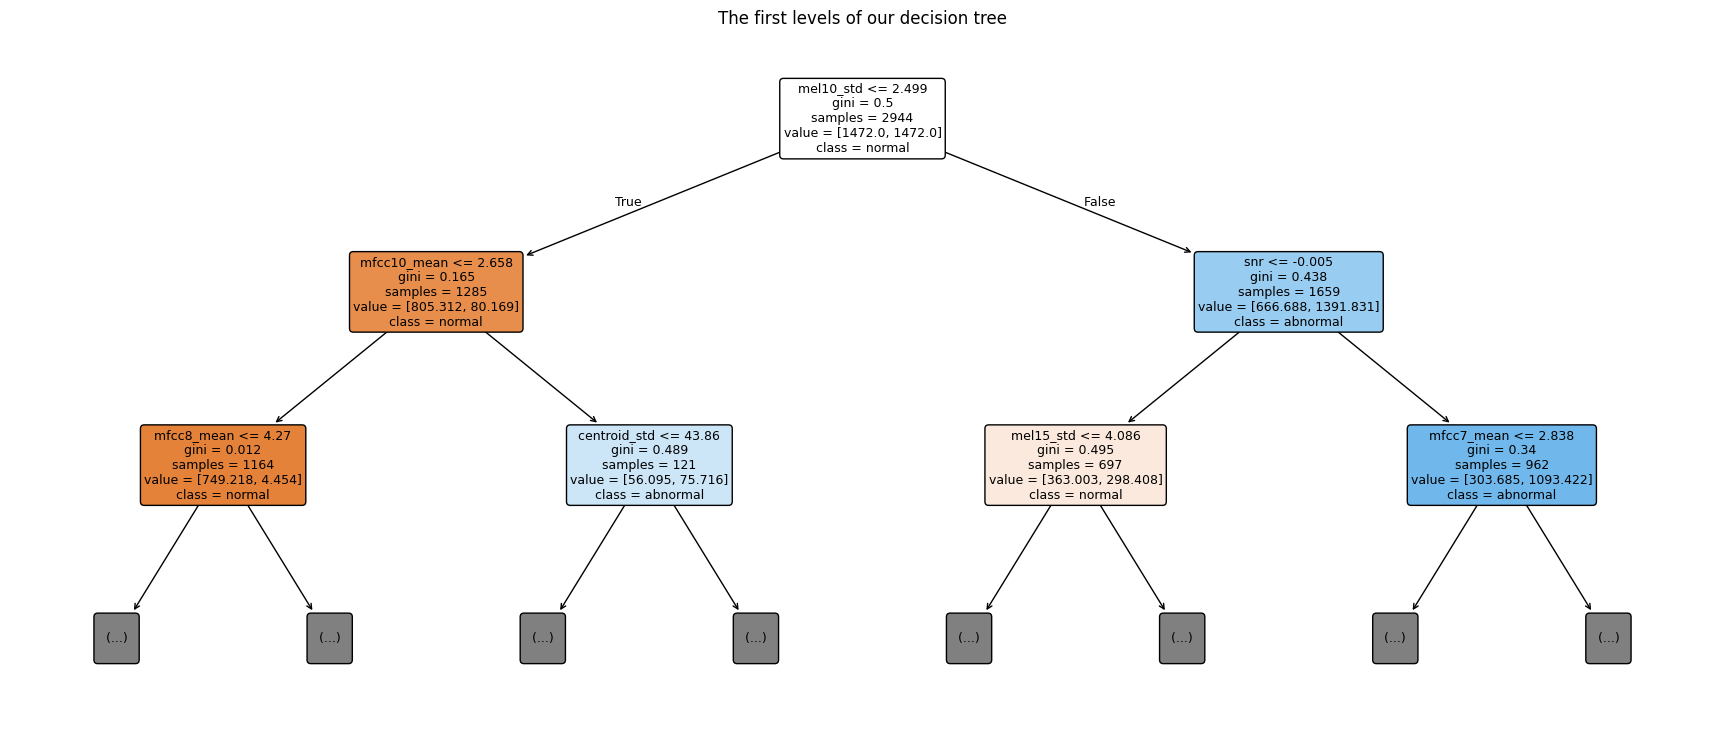

In [16]:
# 7. The tree itself (only the first 3 levels, the whole tree is too big to read)
# In each box: the gini (or entropy) of the box,
# samples = how many train wavs arrive in the box, value = [normal, abnormal] in the box (weighted),
# class = what the tree answers for them. True = the question is true -> go left.
# (with class_weight="balanced" the 2 classes weigh the same, so the first box is 50/50: gini = 0.5 or entropy = 1)
plt.figure(figsize=(22, 9))
plot_tree(final_tree, max_depth=2, feature_names=names_of_features, class_names=["normal", "abnormal"],
          filled=True, rounded=True, fontsize=9)
plt.title("The first levels of our decision tree")
plt.savefig(plots_folder + "tp4_tree.png")
plt.show()

In [17]:
# ==================== MLflow (Service 6): this model in its own run ====================
# the server and our experiment, again here: even if we run only this cell, the run goes to audio_benchmark_final
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark_final")

if best_features == "26 MFCC":
    features_param = "MFCC mean + std (26)"
else:
    features_param = "extended features (72)"

run_name = "decision_tree_" + best_criterion + "_depth" + str(best_depth)
with mlflow.start_run(run_name=run_name):
    # 1. params = the settings we chose
    mlflow.log_param("model", "DecisionTree")
    mlflow.log_param("criterion", best_criterion)
    mlflow.log_param("max_depth", best_depth)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("n_folds", 3)
    mlflow.log_param("features", features_param)
    mlflow.log_param("seconds", SECONDS if best_features == "26 MFCC" else "whole wav")
    mlflow.log_param("sample_rate", SR)
    mlflow.log_param("n_features", X_train.shape[1])
    mlflow.log_param("protocol", "settings + 3 folds on the 80% train part (validation), final tree tested on the 20%")
    mlflow.log_param("n_train", len(y_train))
    mlflow.log_param("n_test", len(y_test))

    # 2. metrics = validation (the mean of the 3 folds, the same names as the other runs) + test
    for metric in metrics:
        mlflow.log_metric("mean_" + metric, table[metric].mean())
        mlflow.log_metric("test_" + metric, test_results[metric])
    for r in results:    # the results of each fold, also here: fold1_accuracy, fold1_precision, ..., fold3_auc
        for metric in metrics:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

    # 3. artifacts = the figures of this notebook: plots/validation/ and plots/test/
    mlflow.log_artifact(plots_folder + "tp4_choose_depth.png", artifact_path="plots/validation")
    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp4_tree_val_fold" + str(fold) + ".png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp4_tree_val_summary.png", artifact_path="plots/validation")
    mlflow.log_artifact(plots_folder + "tp4_tree_test.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp4_tree_test_report.txt", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp4_feature_importance.png", artifact_path="plots/test")
    mlflow.log_artifact(plots_folder + "tp4_tree.png", artifact_path="plots/test")

    # 4. the model: the final tree (trained on the 80% part, the one that was tested)
    mlflow.sklearn.log_model(final_tree, "model", input_example=X_train[:5].astype(np.float32))

    # 5. the 3 folds: 1 small run per fold INSIDE this run (nested=True), with its training and validation results
    for r in results:
        with mlflow.start_run(run_name=run_name + "_fold" + str(r["fold"]), nested=True):
            mlflow.log_param("fold", r["fold"])
            for metric in ["accuracy", "precision", "recall", "f1"]:
                mlflow.log_metric("train_" + metric, r["train_" + metric])    # on the 2/3 train wavs of the fold
                mlflow.log_metric("val_" + metric, r[metric])                 # on the 1/3 validation wavs (never seen)
            mlflow.log_metric("val_auc", r["auc"])
            mlflow.log_artifact(plots_folder + "tp4_tree_val_fold" + str(r["fold"]) + ".png",
                                artifact_path="plots/validation")

🏃 View run decision_tree_gini_depth8_fold1 at: http://localhost:5000/#/experiments/2/runs/57409900d32b49339ad63aa5413ac022
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run decision_tree_gini_depth8_fold2 at: http://localhost:5000/#/experiments/2/runs/f94351145c89429485c434373b15e5cf
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run decision_tree_gini_depth8_fold3 at: http://localhost:5000/#/experiments/2/runs/6e3af43c62ed4684b76f7b304968d67d
🧪 View experiment at: http://localhost:5000/#/experiments/2


🏃 View run decision_tree_gini_depth8 at: http://localhost:5000/#/experiments/2/runs/47424f6a1530453ea83fc4e6e705cc6f
🧪 View experiment at: http://localhost:5000/#/experiments/2


In [18]:
# All the runs of the experiment, the highest validation recall first:
# the project keeps the model with the highest recall of abnormal (the sick hearts)
runs = mlflow.search_runs(experiment_names=["audio_benchmark_final"])
runs = runs[runs["metrics.mean_recall"].notna() & runs["metrics.test_recall"].notna()]    # the final main runs only
columns = ["tags.mlflow.runName", "params.model", "params.features", "metrics.mean_recall", "metrics.mean_f1",
           "metrics.test_recall", "metrics.test_f1", "metrics.test_auc"]
ipd.display(runs[columns].sort_values("metrics.mean_recall", ascending=False).round(3))

,tags.mlflow.runName,params.model,params.features,metrics.mean_recall,metrics.mean_f1,metrics.test_recall,metrics.test_f1,metrics.test_auc
3,cnn,CNN,"mel spectrogram 40 x 157 (5 s, 2000 Hz)",0.938,0.628,0.909,0.661,0.932
4,decision_tree_gini_depth8,DecisionTree,extended features (72),0.778,0.660,0.788,0.686,0.853
